In [2]:
#imports
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [3]:
#reading file
base_path = Path.cwd()
df = pd.read_parquet(f"{base_path}/clean_telemetry.parquet")
df.head()

,session,completedLaps,track_segment,speedKmh,gas,brake,steerAngle,gear,rpms,cleanLaps,iCurrentTime,carCoordinates_x,carCoordinates_y,carCoordinates_z
0,1,5,0,228.949947,1.0,0.0,8.630015e-03,5.0,6396.500000,114.831,30.0,-206.454292,-8.282767,410.635498
1,1,5,1,228.823316,1.0,0.0,2.859690e-03,5.0,6401.500000,114.831,117.5,-206.023911,-8.253204,405.140432
2,1,5,2,229.408194,1.0,0.0,3.904025e-08,5.0,6416.600000,114.831,210.6,-205.510947,-8.224428,399.237726
3,1,5,3,229.947507,1.0,0.0,9.437772e-13,5.0,6423.400000,114.831,297.6,-205.014914,-8.197428,393.709320
4,1,5,4,230.514862,1.0,0.0,2.227238e-04,5.0,6450.333333,114.831,390.5,-204.475446,-8.163259,387.792353


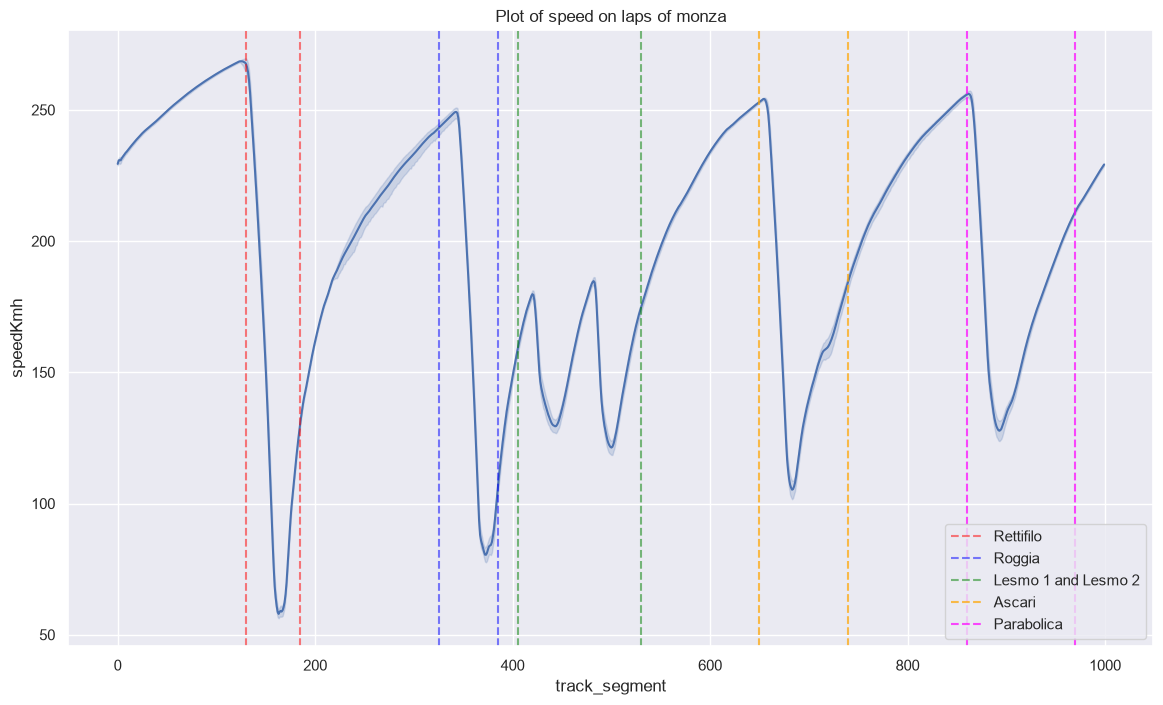

In [4]:
#ploting of change in speed on given curves on monza
plt.figure(figsize=(14,8))
sns.set_theme()
sns.lineplot(data=df , x="track_segment" , y="speedKmh")
plt.vlines(x=[130, 185], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="red", linestyle="--", alpha=0.5, label="Rettifilo")
plt.vlines(x=[325, 385], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="blue", linestyle="--", alpha=0.5, label="Roggia")
plt.vlines(x=[405, 530], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="green", linestyle="--", alpha=0.5, label="Lesmo 1 and Lesmo 2")
plt.vlines(x=[650, 740], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="orange", linestyle="--", alpha=0.7, label="Ascari")        
plt.vlines(x=[860, 970], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="magenta", linestyle="--", alpha=0.7, label="Parabolica")           
plt.title("Plot of speed on laps of monza")
plt.legend()
plt.show()

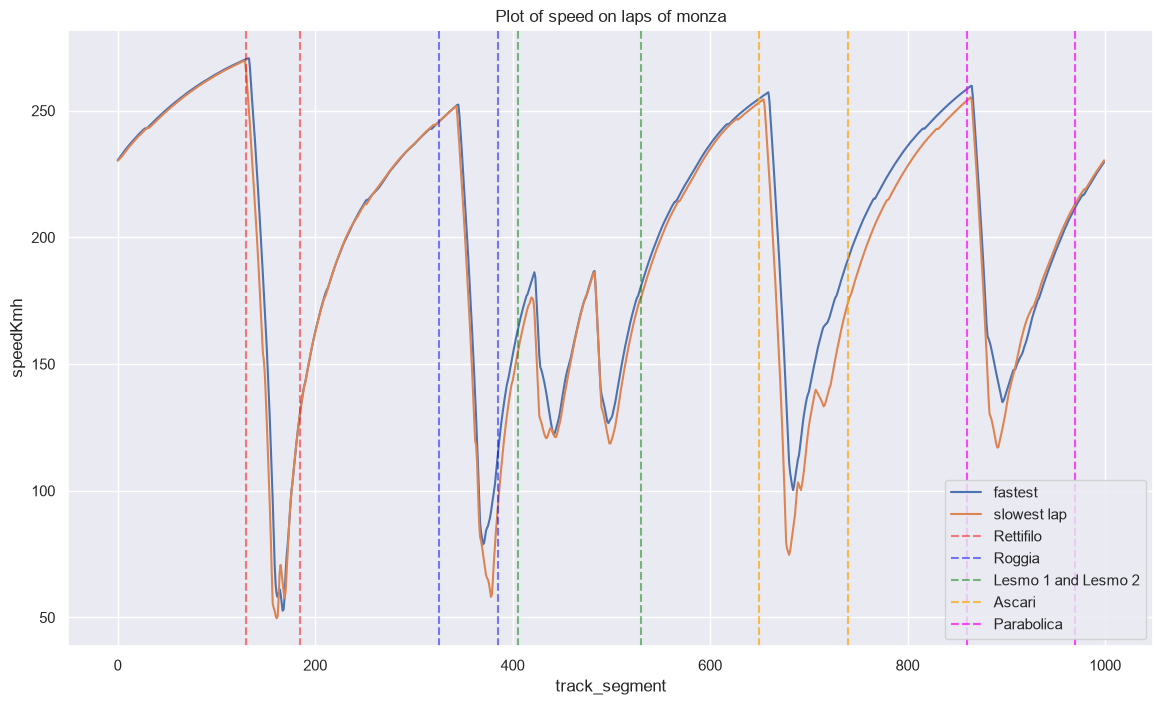

In [ ]:
#Plot of diffrence of speed  between the slowest and fastest lap
df["cleanLaps"] = df["cleanLaps"].round(3)
fastest_lap = df[df["cleanLaps"] == df["cleanLaps"].min()]
slowest_lap = df[df["cleanLaps"] == df["cleanLaps"].max()]
plt.figure(figsize=(14,8))
sns.lineplot(fastest_lap , label="fastest", x="track_segment" , y="speedKmh")
sns.lineplot(slowest_lap , label="slowest lap" , x="track_segment" , y="speedKmh")
plt.vlines(x=[130, 185], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="red", linestyle="--", alpha=0.5, label="Rettifilo")
plt.vlines(x=[325, 385], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="blue", linestyle="--", alpha=0.5, label="Roggia")
plt.vlines(x=[405, 530], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="green", linestyle="--", alpha=0.5, label="Lesmo 1 and Lesmo 2")
plt.vlines(x=[650, 740], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="orange", linestyle="--", alpha=0.7, label="Ascari")        
plt.vlines(x=[860, 970], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="magenta", linestyle="--", alpha=0.7, label="Parabolica")           
plt.title("Plot of speed on laps of monza")
plt.legend()
plt.show()

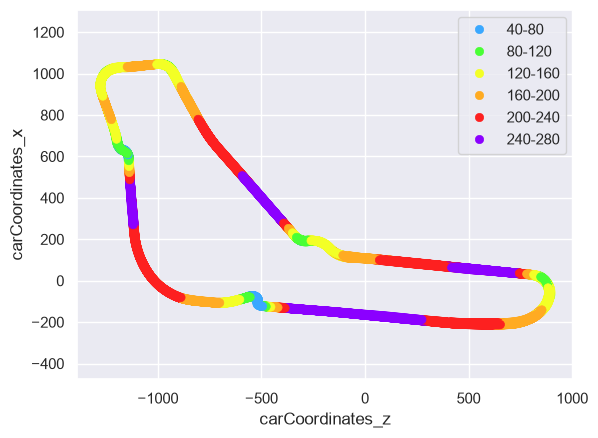

In [ ]:
#Heat map of average speed at every segment of track
carCoordinates = df[["carCoordinates_x" , "carCoordinates_z"]]
df["speedCategory"] = pd.cut(
    df["speedKmh"],
    bins = [40,80,120,160,200,240,280],
    labels=['40-80', '80-120', '120-160', '160-200', '200-240', '240-280' ]
)
custom_palette = {
    '40-80':   '#3aa8ff',
    '80-120':  '#49ff35',
    '120-160': '#f3ff26',
    '160-200': '#ffab22',
    '200-240': '#fd2020',
    '240-280': '#8b00ff',
    
}

sns.scatterplot(carCoordinates , x="carCoordinates_z" , y="carCoordinates_x", hue=df["speedCategory"] ,palette=custom_palette , edgecolor=None)
plt.axis("equal")
plt.legend()
plt.show()

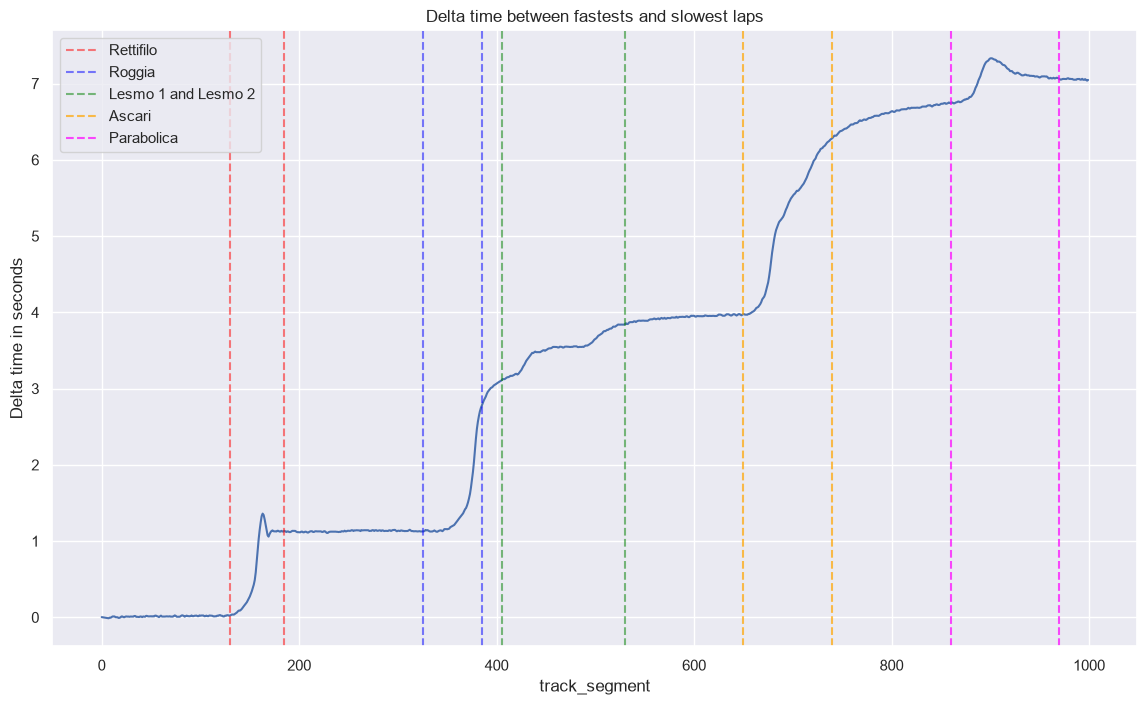

In [ ]:
#Plot of delta time between slowest and fastets laps
delta = (slowest_lap.set_index("track_segment")["iCurrentTime"] - fastest_lap.set_index("track_segment")["iCurrentTime"])/1000
plt.figure(figsize=(14,8))
sns.lineplot( x=delta.index , y=delta.values)
plt.vlines(x=[130, 185], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="red", linestyle="--", alpha=0.5, label="Rettifilo")
plt.vlines(x=[325, 385], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="blue", linestyle="--", alpha=0.5, label="Roggia")
plt.vlines(x=[405, 530], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="green", linestyle="--", alpha=0.5, label="Lesmo 1 and Lesmo 2")
plt.vlines(x=[650, 740], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="orange", linestyle="--", alpha=0.7, label="Ascari")        
plt.vlines(x=[860, 970], ymin=0, ymax=1, transform=plt.gca().get_xaxis_transform(),
           color="magenta", linestyle="--", alpha=0.7, label="Parabolica")    
plt.legend()
plt.title("Delta time between fastests and slowest laps")
plt.ylabel("Delta time in seconds")
plt.show()

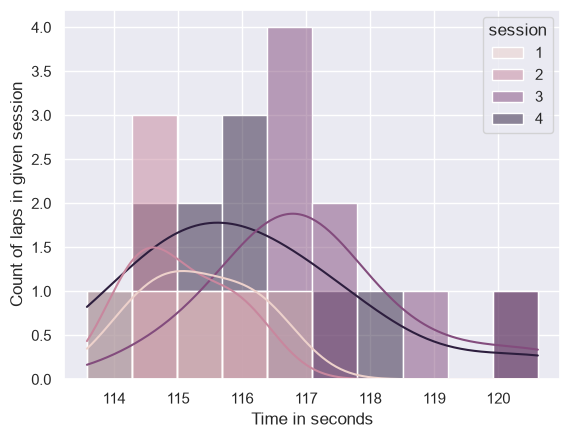

In [ ]:
#Plot of progression in laptime during each session
cleanLaps = df.groupby(["session" , "completedLaps"])["cleanLaps"].first().reset_index()
sns.histplot(data=cleanLaps, kde=True , bins=10 , hue="session" , x="cleanLaps")
plt.xlabel("Time in seconds")
plt.ylabel("Count of laps in given session")
plt.show()